In [2]:
import pandas, sklearn, xgboost, shap
print("All good!")                                                              

All good!


In [3]:
import pandas as pd

df = pd.read_csv("../data/creditcard.csv")
print(df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/creditcard.csv'

In [ ]:
print(df["Class"].value_counts())
print("Fraud %:", df["Class"].mean() * 100)

Class
0    284315
1       492
Name: count, dtype: int64
Fraud %: 0.1727485630620034


In [ ]:
print(df.isnull().sum().sum())
print(df.duplicated().sum())

0
1081


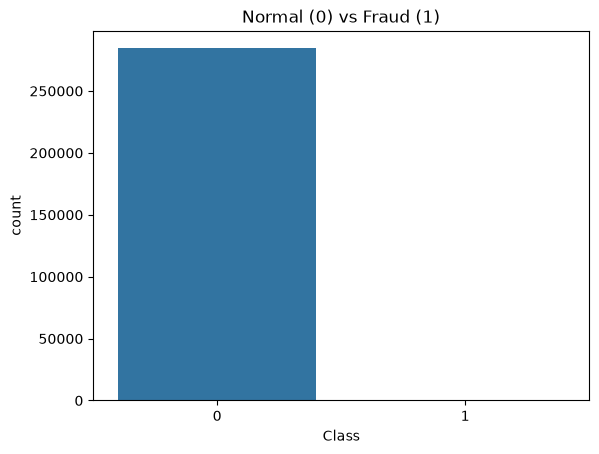

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="Class", data=df)
plt.title("Normal (0) vs Fraud (1)")
plt.savefig("../reports/figures/class_imbalance.png", dpi=150, bbox_inches="tight")
plt.show()

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


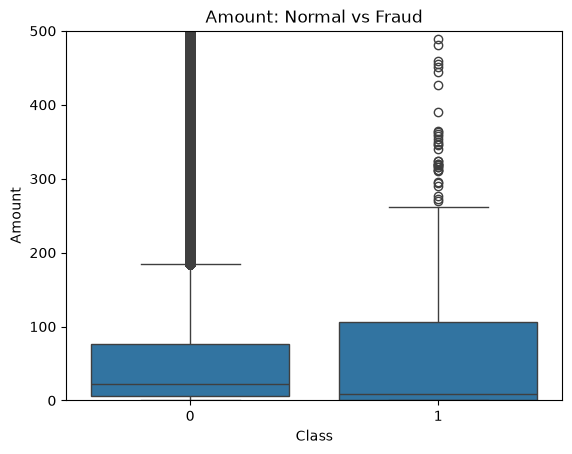

In [ ]:
print(df.groupby("Class")["Amount"].describe())

sns.boxplot(x="Class", y="Amount", data=df)
plt.ylim(0, 500)
plt.title("Amount: Normal vs Fraud")
plt.savefig("../reports/figures/amount_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

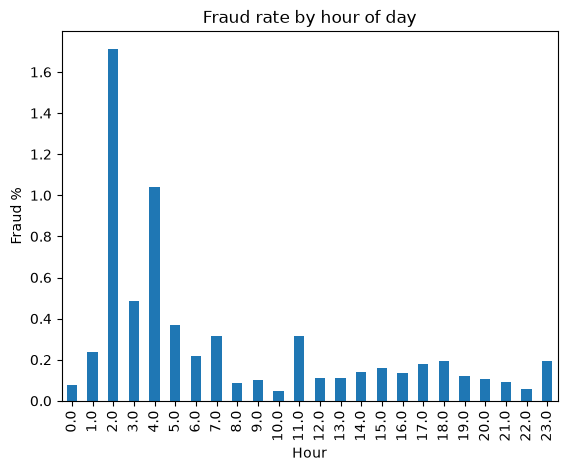

In [ ]:
df["Hour"] = (df["Time"] // 3600) % 24

fraud_by_hour = df.groupby("Hour")["Class"].mean() * 100
fraud_by_hour.plot(kind="bar")
plt.ylabel("Fraud %")
plt.title("Fraud rate by hour of day")
plt.savefig("../reports/figures/fraud_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(["Class", "Hour"], axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Amount mariyu Time ni scale cheyadam (train meeda matrame fit)
scaler = StandardScaler()
X_train[["Amount", "Time"]] = scaler.fit_transform(X_train[["Amount", "Time"]])
X_test[["Amount", "Time"]] = scaler.transform(X_test[["Amount", "Time"]])

print(X_train.shape, X_test.shape)
print("Train fraud:", y_train.sum(), "| Test fraud:", y_test.sum())

(227845, 30) (56962, 30)
Train fraud: 394 | Test fraud: 98


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=100, max_depth=10,
                                           class_weight="balanced_subsample",
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                             scale_pos_weight=ratio, eval_metric="aucpr",
                             random_state=42),
}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_train, y_train)

print("Done!")

Training LogisticRegression ...
Training RandomForest ...
Training XGBoost ...
Done!


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "PR-AUC": average_precision_score(y_test, proba),
    })

results = pd.DataFrame(rows).round(3)
results.to_csv("../reports/model_results.csv", index=False)
results

,Model,Precision,Recall,F1,PR-AUC
0,LogisticRegression,0.061,0.918,0.114,0.716
1,RandomForest,0.835,0.827,0.831,0.822
2,XGBoost,0.844,0.827,0.835,0.865


In [ ]:
import shap
import numpy as np

xgb_model = models["XGBoost"]

explainer = shap.TreeExplainer(xgb_model)
sv = explainer(X_test)
print("SHAP done")

SHAP done


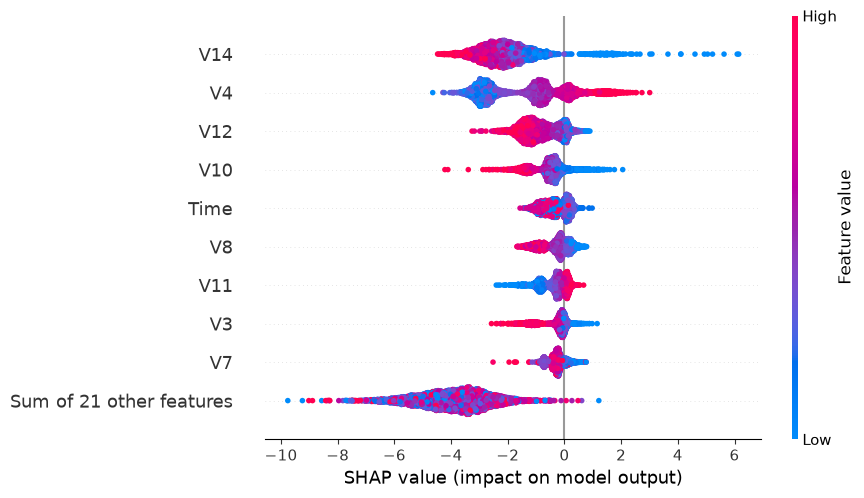

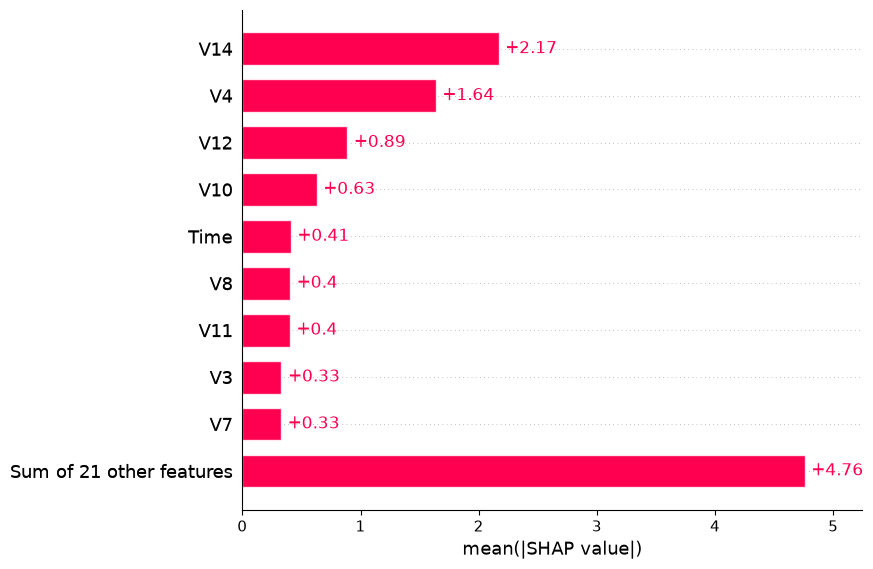

In [ ]:
plt.figure()
shap.plots.beeswarm(sv[:5000], show=False)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure()
shap.plots.bar(sv[:5000], show=False)
plt.savefig("../reports/figures/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

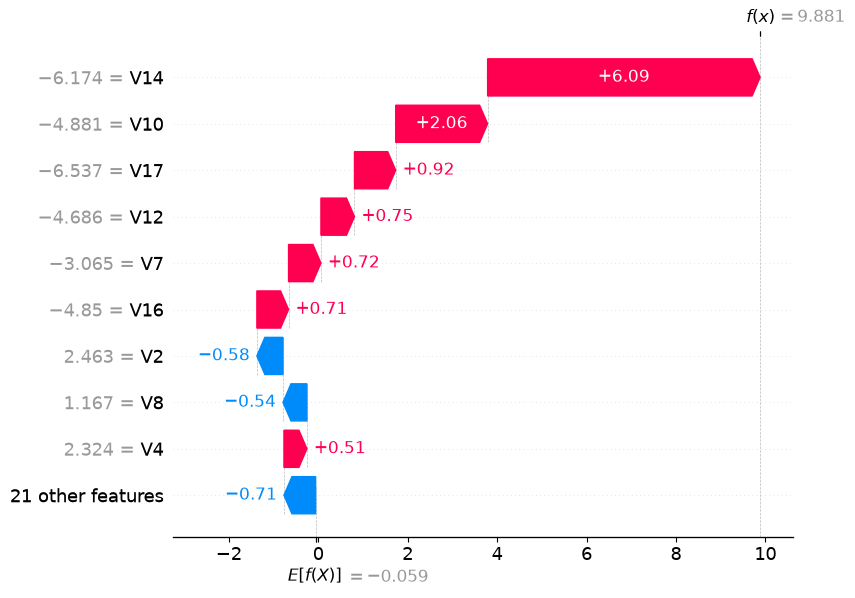

In [ ]:
pos = np.where(y_test.values == 1)[0][0]   # test lo first fraud transaction

plt.figure()
shap.plots.waterfall(sv[pos], show=False)
plt.savefig("../reports/figures/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
import joblib
joblib.dump(xgb_model, "../models/xgb_card.pkl")
joblib.dump(scaler, "../models/scaler_card.pkl")

['../models/scaler_card.pkl']

In [4]:
import joblib
import pandas as pd
from sklearn.metrics import confusion_matrix

# 1. Sample data (98 frauds + 400 normal, test split nundi)
df = pd.read_csv("../sample/card_sample.csv")

# 2. Saved scaler and Kaggle XGBoost model
scaler = joblib.load("../models/scaler_card.pkl")
obj = joblib.load("../models/xgb_card_kaggle.bak")
model = obj["model"] if isinstance(obj, dict) else obj

# 3. Scale Time and Amount (scaler fit chesina order lo)
X = df.drop(columns=["Class"]).copy()
y = df["Class"]
cols = list(scaler.feature_names_in_)
X[cols] = scaler.transform(X[cols])

# 4. Predict and confusion matrix
if hasattr(model, "feature_names_in_"):
    X = X[list(model.feature_names_in_)]
pred = model.predict(X)
tn, fp, fn, tp = confusion_matrix(y, pred).ravel()

print("TP =", tp, " FN =", fn, "  (report: TP=81, FN=17)")
print("Fraud total in sample:", int(y.sum()), "(should be 98)")

TP = 81  FN = 17   (report: TP=81, FN=17)
Fraud total in sample: 98 (should be 98)
